<a href="https://colab.research.google.com/github/Mugunth8365/Data-Science-Journey-/blob/main/Day%204%20Data%20Sience%20journey.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [419]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("titanic")

In [420]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
None


In [421]:
print(df.groupby("pclass")["age"].aggregate(["min","mean","max"]))

         min       mean   max
pclass                       
1       0.92  38.233441  80.0
2       0.67  29.877630  70.0
3       0.42  25.140620  74.0


In [422]:
print(df.groupby("embark_town")["who"].count())

embark_town
Cherbourg      168
Queenstown      77
Southampton    644
Name: who, dtype: int64


In [423]:
  print((df.groupby("pclass")["fare"].mean()).sort_values(ascending=False))

pclass
1    84.154687
2    20.662183
3    13.675550
Name: fare, dtype: float64


In [424]:
print(df.groupby(["class","who"])["survived"].mean()*100)

class   who  
First   child     83.333333
        man       35.294118
        woman     97.802198
Second  child    100.000000
        man        8.080808
        woman     90.909091
Third   child     43.103448
        man       11.912226
        woman     49.122807
Name: survived, dtype: float64


/tmp/ipykernel_2174/2175113915.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby(["class","who"])["survived"].mean()*100)


In [425]:
  a=df.pivot_table(values="survived",index="alone",columns="sex",aggfunc="mean")
print(df["fare"].count())
print(a)


891
sex      female      male
alone                    
False  0.712766  0.271084
True   0.785714  0.155718


In [426]:
print(df.groupby("embark_town")["fare"].agg(["mean","count"]))

                  mean  count
embark_town                  
Cherbourg    59.954144    168
Queenstown   13.276030     77
Southampton  27.079812    644


In [427]:
def graph1():
  sns.heatmap(a, annot=True)
  plt.title("Survival rate by sex and alone ")
  plt.show()

In [428]:

  b=df.groupby("who")["survived"].mean()
  print(f"The who group with the highest survival rate is {b.idxmax()}with {b.max()*100}%")

The who group with the highest survival rate is womanwith 75.64575645756457%


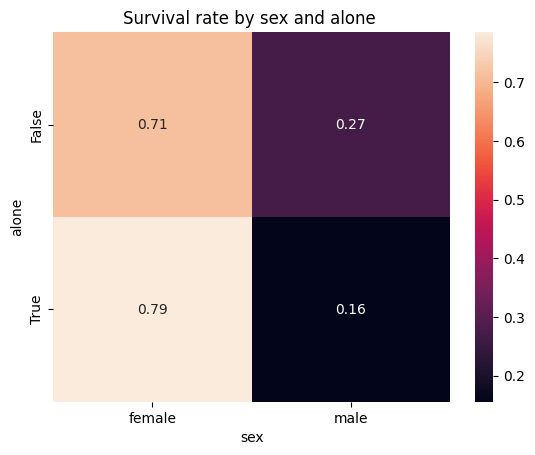

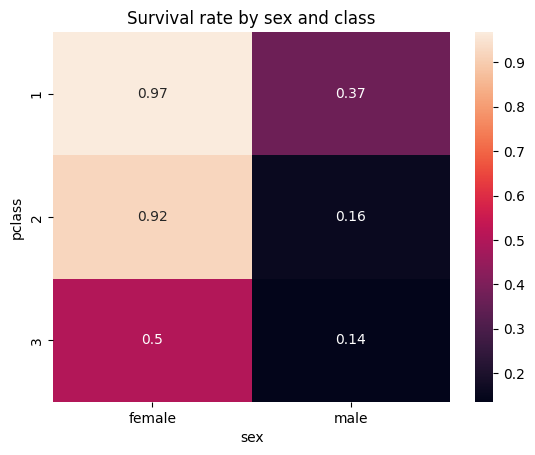

In [429]:
def graph2():
  c=df.pivot_table(values="survived",index="pclass",columns="sex",aggfunc="mean")
  sns.heatmap(c,annot=True)
  plt.title("Survival rate by sex and class")
  plt.show()

graph1()
graph2()
